<a href="https://colab.research.google.com/github/teoespero/Roads_in_Monterey_County/blob/main/Roads_in_Monterey_County.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Roads in Monterey County**

Which roads cross into Salinas, Marina, Seaside, or Monterey? How much of each road is inside city limits?

We're gonna run the cells in order. Try answering the questions before we run the code.

We’ll use 2025 U.S. Census Bureau TIGER/Line Monterey County All Roads and California Places ZIP. and look at primary, secondary, and local roads.

**Install GeoPandas**

In [1]:
%pip -q install 'geopandas>=1.0,<2' pyogrio

**1. Open the data**

The first table has one row per road feature. A street with one name can be split into several features. The second table has one row per city.

We use UTM Zone 10N (EPSG:32610) so the map units are meters. Divide by 1,000 to get kilometers.

In [2]:
from pathlib import Path
from zipfile import is_zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

**Set up the download folder**

In [4]:
BASE = "https://www2.census.gov/geo/tiger/TIGER2025"
DATA = Path("tiger2025")
DATA.mkdir(exist_ok=True)

**Define how to download and open a Census ZIP**

In [6]:
def read_tiger(folder, filename):
    path = DATA / filename
    if not is_zipfile(path):
        response = requests.get(f"{BASE}/{folder}/{filename}", timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
        if not is_zipfile(path):
            raise ValueError(f"Expected a Census ZIP archive at {path}")
    return gpd.read_file(f"zip://{path.resolve()}", engine="pyogrio")

**Load the roads and city boundaries**

In [7]:
road_source = read_tiger("ROADS", "tl_2025_06053_roads.zip")
place_source = read_tiger("PLACE", "tl_2025_06_place.zip")

**Choose the road types and cities**

In [8]:
road_classes = {"S1100": "Primary", "S1200": "Secondary", "S1400": "Local"}
city_names = ["Salinas", "Marina", "Seaside", "Monterey"]

**Prepare the roads and measure their full lengths**

In [9]:
roads = road_source.loc[
    road_source["MTFCC"].isin(road_classes), ["LINEARID", "FULLNAME", "MTFCC", "geometry"]
].rename(columns={"LINEARID": "tiger_id", "FULLNAME": "road_name"}).to_crs(32610)
roads = roads.reset_index(drop=True)
roads["road_id"] = roads.index + 1
roads["road_type"] = roads["MTFCC"].map(road_classes)
roads["road_km"] = roads.geometry.length / 1_000

**Prepare the city boundaries and measure their areas**

In [10]:
cities = place_source.loc[
    place_source["NAME"].isin(city_names) & place_source["MTFCC"].eq("G4110"),
    ["GEOID", "NAME", "geometry"],
].rename(columns={"GEOID": "city_id", "NAME": "city"}).to_crs(32610)
cities = cities.sort_values("city").reset_index(drop=True)
cities["city_area_km2"] = cities.geometry.area / 1_000_000

**Check the layers before joining**

In [11]:
assert set(cities["city"]) == set(city_names) and len(cities) == len(city_names)
assert roads.crs == cities.crs
assert roads.geometry.is_valid.all() and cities.geometry.is_valid.all()

**Look at the two tables**

In [12]:
display(roads[["road_id", "road_name", "road_type", "road_km"]].head())
display(cities[["city_id", "city", "city_area_km2"]].round(2))

,road_id,road_name,road_type,road_km
0,1,N 1st St,Local,1.093855
1,2,N Casanova St,Local,0.219022
2,3,N Doris Watson Pl,Local,0.020376
3,4,N 3rd St,Local,0.883047
4,5,N South Rd,Local,1.533066


,city_id,city,city_area_km2
0,0645778,Marina,25.40
1,0648872,Monterey,31.74
2,0664224,Salinas,60.96
3,0670742,Seaside,23.45


**2. Find which roads meet each city**

Before we run the code, let's make a quick guess on what happens when one road crosses two cities. How many rows will we get? What length will each row show?

The spatial join puts the city name next to the road. Each match gets a row with the full road shape and length. A road that only touches the city line counts as a match, too.

When we run the left and right joins, let's go check the geometry types they print. The left join keeps road lines. The right join keeps city shapes.

**Run the inner spatial join**

In [13]:
matches = gpd.sjoin(roads, cities, how="inner", predicate="intersects")
display(matches[["road_id", "road_name", "road_type", "city", "road_km"]].head(10))

,road_id,road_name,road_type,city,road_km
0,1,N 1st St,Local,Salinas,1.093855
4,5,N South Rd,Local,Seaside,1.533066
6,7,N Madeira Ave,Local,Salinas,2.200046
7,8,N Hebbron Ave,Local,Salinas,0.522802
8,9,N Pearl St,Local,Salinas,0.349119
9,10,N 4th St,Local,Salinas,0.230784
10,11,N 3rd St,Local,Salinas,0.199088
11,12,N 3rd St,Local,Salinas,0.125562
12,13,N South Rd,Local,Seaside,5.581826
12,13,N South Rd,Local,Marina,5.581826


**Count road features by city and road type**

In [14]:
feature_counts = (
    matches.groupby(["city", "road_type"])["road_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=cities["city"], columns=list(road_classes.values()), fill_value=0)
)
display(feature_counts)

road_type,Primary,Secondary,Local
city,,,
Marina,4,0,444
Monterey,6,18,598
Salinas,4,15,1389
Seaside,4,3,467


**Compare left and right joins**

In [15]:
left_join = gpd.sjoin(roads, cities, how="left", predicate="intersects")
right_join = gpd.sjoin(roads, cities, how="right", predicate="intersects")
print("Road features with no match in the four selected cities:", left_join["city_id"].isna().sum())
print("Left join geometry types:", sorted(left_join.geom_type.unique()))
print("Right join geometry types:", sorted(right_join.geom_type.unique()))

Road features with no match in the four selected cities: 12537
Left join geometry types: ['LineString']
Right join geometry types: ['MultiPolygon', 'Polygon']


Change intersects to within below and run the cell again. Which counts change? Think about a road that goes into a city and comes out the other side.

**Try a different match rule**

In [16]:
trial = gpd.sjoin(roads, cities, how="inner", predicate="intersects")
display(trial.groupby("city")["road_id"].nunique().reindex(cities["city"], fill_value=0))

,road_id
city,
Marina,448
Monterey,622
Salinas,1408
Seaside,474


**3. Measure how much road is inside each city**

An intersection overlay cuts the road at the city line and keeps the part inside. A road can have more than one piece inside the same city. If the road only touches at a point, there’s no line to measure.

The old road_km column still shows the full road length. Use the new shapes to calculate inside_km.

**Cut the roads at the city boundaries**

In [17]:
segments = gpd.overlay(roads, cities, how="intersection", keep_geom_type=True)

**Measure the pieces in kilometers**

In [18]:
segments["inside_km"] = segments.geometry.length / 1_000

**Add up the kilometers by city and road type**

In [19]:
length_by_city = (
    segments.groupby(["city", "road_type"])["inside_km"]
    .sum()
    .unstack(fill_value=0)
    .reindex(index=cities["city"], columns=list(road_classes.values()), fill_value=0)
)
display(length_by_city.round(2))
assert (segments["inside_km"] <= segments["road_km"] + 1e-6).all()

road_type,Primary,Secondary,Local
city,,,
Marina,23.88,0.00,148.42
Monterey,36.04,33.76,239.68
Salinas,34.84,18.20,520.75
Seaside,17.55,2.99,193.04


**4. Look at the same road on two maps**

Find the road name in both tables. How long is the full road? How much of it is inside each city? Look at the two maps to see where the road was cut.

In [20]:
multi_city = segments.groupby("road_id")["city_id"].nunique()
candidate = segments.loc[
    segments["road_id"].isin(multi_city[multi_city.gt(1)].index)
    & segments["road_name"].notna()
]
if candidate.empty:
    candidate = segments.loc[segments["inside_km"] < segments["road_km"] - 1e-6]
example_id = candidate.iloc[0]["road_id"]

**Compare the two tables**

In [21]:
display(matches.loc[matches["road_id"].eq(example_id), ["road_id", "road_name", "city", "road_km"]].round(3))
display(segments.loc[segments["road_id"].eq(example_id), ["road_id", "road_name", "city", "inside_km"]].round(3))

,road_id,road_name,city,road_km
131,132,W Blanco Rd,Salinas,9.13
131,132,W Blanco Rd,Marina,9.13


,road_id,road_name,city,inside_km
67,132,W Blanco Rd,Marina,0.744
68,132,W Blanco Rd,Salinas,2.610


**Draw both maps**

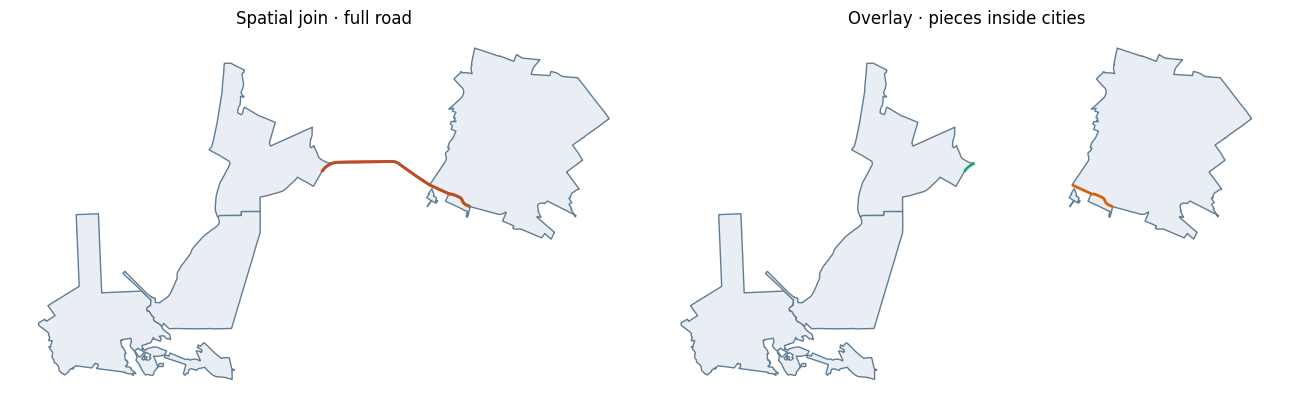

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax in axes:
    cities.plot(ax=ax, facecolor="#e8eef4", edgecolor="#607d94")
    ax.set_axis_off()

matches.loc[matches["road_id"].eq(example_id)].plot(ax=axes[0], color="#be4d25", linewidth=2)
segments.loc[segments["road_id"].eq(example_id)].plot(ax=axes[1], column="city", cmap="Dark2", linewidth=2)
axes[0].set_title("Spatial join · full road")
axes[1].set_title("Overlay · pieces inside cities")
plt.tight_layout()
plt.show()